# Implementing Human-in-the-Loop in LangGraph: The Edit Pattern

## Learning Objectives

By the end of this tutorial, you will be able to:

1. Set up checkpointing in LangGraph (required for human-in-the-loop)
2. Use `interrupt()` to pause workflow execution at critical points
3. Resume workflows with `Command(resume=<value>)` to pass data back to the interrupt
4. Use `interrupt_before` as an alternative interrupt mechanism

## What You'll Build

We'll build an **Email Draft Agent** that:
1. Takes a user's request for an email
2. Generates a draft email using an LLM
3. **Pauses for human review** - allowing the human to edit the draft
4. Proceeds to "send" the email after human review

## Requirements for Human-in-the-Loop in LangGraph

To implement human-in-the-loop, you need:

1. **Checkpointing**: State must be saved so the workflow can pause and resume
2. **Interrupts**: Mechanism to pause execution at specific points
3. **State updates**: Ability to modify state before resuming

## Part 1: Environment Setup

Let's install and import the required packages.

In [16]:
# Install required packages if needed
# Uncomment the following line if you need to install the packages
# !pip install langgraph langchain-openai python-dotenv

In [17]:
# Load environment variables
from dotenv import load_dotenv
import os

# Load API keys from .env file
load_dotenv()

# Verify that keys are loaded
assert os.getenv("OPENAI_API_KEY"), "OPENAI_API_KEY not found in environment"

print("Environment variables loaded successfully!")

Environment variables loaded successfully!


In [18]:
# Import dependencies
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import interrupt, Command
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage, SystemMessage

print("All imports successful!")

All imports successful!


## Part 2: Define the State

Our Email Draft Agent tracks the user's request, the generated draft, and the workflow status.

In [19]:
class EmailAgentState(TypedDict):
    """State schema for the Email Draft Agent."""
    
    # The user's request describing what email they want
    request: str
    
    # The generated email draft (can be edited by human)
    email_draft: str
    
    # Status of the email: 'drafting', 'pending_review', 'sent'
    status: str


print("State schema defined!")
print("\nState fields:")
print("  - request: The user's email request")
print("  - email_draft: The generated draft (editable by human)")
print("  - status: Current workflow status")

State schema defined!

State fields:
  - request: The user's email request
  - email_draft: The generated draft (editable by human)
  - status: Current workflow status


## Part 3: Initialize the LLM

In [20]:
# Initialize the language model
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0.7)

print("LLM initialized: gpt-4o-mini")

LLM initialized: gpt-4o-mini


## Part 4: Create the Workflow Nodes

Our workflow has three nodes:

1. **`generate_draft`**: Uses the LLM to create an email draft
2. **`human_review`**: Pauses execution with `interrupt()`, allowing human review and editing
3. **`send_email`**: Simulates sending the email

### How `interrupt()` Works

The `interrupt()` function is key to human-in-the-loop:
- When called, execution pauses immediately
- The interrupt payload is returned to the caller (for display/context)
- State is saved via the checkpointer
- When resumed with `Command(resume=<value>)`, the `<value>` is **returned by `interrupt()`**
- The node can then use this returned value to update state accordingly

In [21]:
def generate_draft(state: EmailAgentState) -> dict:
    """
    Generates an email draft based on the user's request.
    
    This node uses the LLM to create a professional email draft
    that the human can later review and edit.
    """
    request = state["request"]
    
    print(f"Generating email draft for request: {request[:50]}...")
    
    system_prompt = """You are a professional email writing assistant.
    
Write a clear, professional email based on the user's request.
Include an appropriate subject line, greeting, body, and sign-off.
Keep the tone professional but friendly.

Format the output as:
Subject: [subject line]

[email body]
"""
    
    messages = [
        SystemMessage(content=system_prompt),
        HumanMessage(content=f"Write an email for: {request}")
    ]
    
    response = llm.invoke(messages)
    
    print("Draft generated successfully!")
    
    return {
        "email_draft": response.content,
        "status": "pending_review"
    }


print("generate_draft node created!")

generate_draft node created!


In [22]:
def human_review(state: EmailAgentState) -> dict:
    """
    Pauses for human review and potential editing of the email draft.
    
    This node implements the HITL interrupt. When execution reaches this point:
    1. The interrupt() function pauses the workflow and returns control to the caller
    2. A human can review the draft and resume with Command(resume=<value>)
    3. The value passed to Command(resume=...) is returned by interrupt()
    """
    print("\n" + "=" * 60)
    print("HUMAN REVIEW REQUIRED")
    print("=" * 60)
    print("\nCurrent email draft:")
    print("-" * 40)
    print(state["email_draft"])
    print("-" * 40)
    
    # This interrupt pauses execution and returns control to the caller
    # When resumed with Command(resume=<value>), the value is returned here
    human_input = interrupt({
        "message": "Please review the email draft. You can edit it before sending.",
        "current_draft": state["email_draft"],
    })
    
    # human_input contains whatever was passed to Command(resume=...)
    # If it's a string, treat it as the edited draft
    # If it's True (from Command(resume=True)), keep the original draft
    print("\nHuman review complete. Proceeding with the email.")
    
    if isinstance(human_input, str):
        # Human provided an edited draft
        return {"email_draft": human_input, "status": "reviewed"}
    else:
        # Human approved as-is (Command(resume=True))
        return {"status": "reviewed"}


print("human_review node created!")

human_review node created!


In [23]:
def send_email(state: EmailAgentState) -> dict:
    """
    Simulates sending the email.
    
    In a production system, this would integrate with an email API
    (e.g., SendGrid, AWS SES, Gmail API).
    
    This node only executes AFTER human review, ensuring the human
    has had a chance to review and edit the draft.
    """
    print("\n" + "=" * 60)
    print("SENDING EMAIL")
    print("=" * 60)
    print("\nFinal email being sent:")
    print("-" * 40)
    print(state["email_draft"])
    print("-" * 40)
    print("\nEmail sent successfully!")
    
    return {"status": "sent"}


print("send_email node created!")

send_email node created!


## Part 5: Build the Graph with Checkpointing

The **checkpointer** is required for human-in-the-loop because:
1. State must be persisted when the interrupt pauses execution
2. When resumed, the workflow restores from saved state
3. State updates from the human are applied correctly

We use `MemorySaver` here (in-memory). For production, use `SqliteSaver` or `PostgresSaver`.

In [24]:
# Create the state graph
workflow = StateGraph(EmailAgentState)

# Add nodes to the graph
workflow.add_node("generate_draft", generate_draft)
workflow.add_node("human_review", human_review)
workflow.add_node("send_email", send_email)

# Define the edges (linear flow)
workflow.add_edge(START, "generate_draft")
workflow.add_edge("generate_draft", "human_review")
workflow.add_edge("human_review", "send_email")
workflow.add_edge("send_email", END)

# Create the checkpointer (required for HITL)
checkpointer = MemorySaver()

# Compile the graph with the checkpointer
app = workflow.compile(checkpointer=checkpointer)

print("Graph compiled with checkpointing!")
print("\nWorkflow structure:")
print("  START --> generate_draft --> human_review (INTERRUPT) --> send_email --> END")

Graph compiled with checkpointing!

Workflow structure:
  START --> generate_draft --> human_review (INTERRUPT) --> send_email --> END


### Visualize the Graph (Optional)

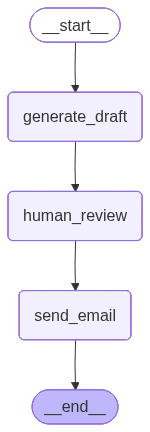

In [25]:
# Try to visualize the graph
try:
    from IPython.display import Image, display
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception as e:
    print(f"Visualization not available: {e}")
    print("\nGraph structure: START -> generate_draft -> human_review -> send_email -> END")

## Part 6: Run the Workflow - Initial Execution

The workflow will generate a draft and pause at the `human_review` node. We must provide a `thread_id` to uniquely identify this execution for later resumption.

In [26]:
# Define our email request
email_request = "Write a professional email to my manager requesting time off next Friday for a medical appointment."

print("Email Request:")
print(f"  {email_request}")
print("\n" + "=" * 60)
print("PHASE 1: Starting workflow (will pause for human review)")
print("=" * 60)

# Configuration with thread_id for state tracking
config = {"configurable": {"thread_id": "email-session-1"}}

# Initial state
initial_state = {
    "request": email_request,
    "email_draft": "",
    "status": "drafting"
}

# Invoke the graph - it will pause at the interrupt
result = app.invoke(initial_state, config)

print("\n" + "=" * 60)
print("Workflow paused for human review!")
print("=" * 60)

Email Request:
  Write a professional email to my manager requesting time off next Friday for a medical appointment.

PHASE 1: Starting workflow (will pause for human review)
Generating email draft for request: Write a professional email to my manager requestin...
Draft generated successfully!

HUMAN REVIEW REQUIRED

Current email draft:
----------------------------------------
Subject: Request for Time Off Next Friday

Dear [Manager's Name],

I hope this message finds you well. I am writing to formally request time off next Friday, [insert date], due to a scheduled medical appointment. 

I will ensure that all my responsibilities are managed and that any pending tasks are completed before my absence. Please let me know if you need any further information or if there are forms I should fill out to formalize this request.

Thank you for your understanding. I appreciate your support.

Best regards,

[Your Name]  
[Your Job Title]  
[Your Contact Information]  
---------------------------

## Part 7: Inspect the Interrupt

When paused, the result contains interrupt information including the payload we passed to `interrupt()`.

In [27]:
print("INSPECTING PAUSED STATE")
print("=" * 60)

# Check current state values
print("\nCurrent State:")
print(f"  Request: {result['request'][:50]}...")
print(f"  Status: {result['status']}")
print(f"  Draft length: {len(result.get('email_draft', ''))} characters")

# Check interrupt information
if '__interrupt__' in result:
    print("\nInterrupt Information:")
    for interrupt_info in result['__interrupt__']:
        interrupt_value = interrupt_info.value
        print(f"  Message: {interrupt_value.get('message')}")

print("\n" + "=" * 60)
print("You can now review the draft and decide how to proceed.")
print("=" * 60)

INSPECTING PAUSED STATE

Current State:
  Request: Write a professional email to my manager requestin...
  Status: pending_review
  Draft length: 591 characters

Interrupt Information:
  Message: Please review the email draft. You can edit it before sending.

You can now review the draft and decide how to proceed.


## Part 8: Review the Draft

In [28]:
# Display the current draft for review
print("CURRENT EMAIL DRAFT FOR REVIEW")
print("=" * 60)
print()

current_draft = result.get('email_draft', '')
print(current_draft)

print()
print("=" * 60)
print("\nReview options:")
print("  1. Accept as-is: Use Command(resume=True)")
print("  2. Edit the draft: Use Command(resume='your edited version')")

CURRENT EMAIL DRAFT FOR REVIEW

Subject: Request for Time Off Next Friday

Dear [Manager's Name],

I hope this message finds you well. I am writing to formally request time off next Friday, [insert date], due to a scheduled medical appointment. 

I will ensure that all my responsibilities are managed and that any pending tasks are completed before my absence. Please let me know if you need any further information or if there are forms I should fill out to formalize this request.

Thank you for your understanding. I appreciate your support.

Best regards,

[Your Name]  
[Your Job Title]  
[Your Contact Information]  


Review options:
  1. Accept as-is: Use Command(resume=True)
  2. Edit the draft: Use Command(resume='your edited version')


## Part 9: Resume with Human Edits

Use `Command(resume=<value>)` to pass a value back to the `interrupt()` call. The value is returned by `interrupt()`, and the node can use it to update state.

In [29]:
# Create an edited version of the email
edited_draft = """Subject: Time Off Request - Friday, [Date]

Hi [Manager's Name],

I am writing to request time off next Friday for a medical appointment scheduled at 10:00 AM. I expect to be out for approximately half the day.

I will ensure all urgent tasks are completed before I leave and will be available by phone for any critical matters.

Please let me know if you need any additional information.

Thank you,
[Your Name]"""

print("HUMAN EDIT: Modified email draft")
print("=" * 60)
print()
print(edited_draft)
print()
print("=" * 60)

HUMAN EDIT: Modified email draft

Subject: Time Off Request - Friday, [Date]

Hi [Manager's Name],

I am writing to request time off next Friday for a medical appointment scheduled at 10:00 AM. I expect to be out for approximately half the day.

I will ensure all urgent tasks are completed before I leave and will be available by phone for any critical matters.

Please let me know if you need any additional information.

Thank you,
[Your Name]



In [30]:
print("PHASE 2: Resuming workflow with human edits")
print("=" * 60)

# Resume the workflow with our edited draft
# Command(resume=<value>) passes the value back to the interrupt() call and continues execution
# The state update is applied, and the workflow continues past the interrupt point
final_result = app.invoke(
    Command(resume=edited_draft),
    config  # Same config with same thread_id to resume the right session
)

print("\n" + "=" * 60)
print("WORKFLOW COMPLETE")
print("=" * 60)
print(f"\nFinal Status: {final_result['status']}")

PHASE 2: Resuming workflow with human edits

HUMAN REVIEW REQUIRED

Current email draft:
----------------------------------------
Subject: Request for Time Off Next Friday

Dear [Manager's Name],

I hope this message finds you well. I am writing to formally request time off next Friday, [insert date], due to a scheduled medical appointment. 

I will ensure that all my responsibilities are managed and that any pending tasks are completed before my absence. Please let me know if you need any further information or if there are forms I should fill out to formalize this request.

Thank you for your understanding. I appreciate your support.

Best regards,

[Your Name]  
[Your Job Title]  
[Your Contact Information]  
----------------------------------------

Human review complete. Proceeding with the email.

SENDING EMAIL

Final email being sent:
----------------------------------------
Subject: Time Off Request - Friday, [Date]

Hi [Manager's Name],

I am writing to request time off next F

## Part 10: Alternative - Resume Without Changes

If the draft is good as-is, use `Command(resume=True)` to continue without modifications.

In [31]:
# New email request
email_request_2 = "Write a thank you email to a colleague who helped me with a project presentation."

print("NEW EMAIL REQUEST:")
print(f"  {email_request_2}")
print("\n" + "=" * 60)
print("Starting new workflow session...")
print("=" * 60)

# New session with different thread_id
config_2 = {"configurable": {"thread_id": "email-session-2"}}

initial_state_2 = {
    "request": email_request_2,
    "email_draft": "",
    "status": "drafting"
}

# Start the workflow
result_2 = app.invoke(initial_state_2, config_2)

print("\nWorkflow paused. Draft generated:")
print("-" * 40)
print(result_2.get('email_draft', '')[:500])
print("-" * 40)

NEW EMAIL REQUEST:
  Write a thank you email to a colleague who helped me with a project presentation.

Starting new workflow session...
Generating email draft for request: Write a thank you email to a colleague who helped ...
Draft generated successfully!

HUMAN REVIEW REQUIRED

Current email draft:
----------------------------------------
Subject: Thank You for Your Support!

Hi [Colleague's Name],

I hope this message finds you well. I wanted to take a moment to express my heartfelt thanks for your assistance with the project presentation. Your insights and suggestions were invaluable, and I truly appreciate the time and effort you dedicated to helping me prepare.

The presentation was a success, and I couldn’t have done it without your support. It’s a pleasure to work with someone as knowledgeable and collaborative as you.

Thanks once again for your help! I look forward to our continued collaboration on future projects.

Best regards,

[Your Name]  
[Your Job Title]  
[Your Contac

In [32]:
print("APPROVING DRAFT AS-IS")
print("=" * 60)

# Resume without changes - the draft looks good!
final_result_2 = app.invoke(
    Command(resume=True),  # No updates, just resume
    config_2
)

print(f"\nFinal Status: {final_result_2['status']}")

APPROVING DRAFT AS-IS

HUMAN REVIEW REQUIRED

Current email draft:
----------------------------------------
Subject: Thank You for Your Support!

Hi [Colleague's Name],

I hope this message finds you well. I wanted to take a moment to express my heartfelt thanks for your assistance with the project presentation. Your insights and suggestions were invaluable, and I truly appreciate the time and effort you dedicated to helping me prepare.

The presentation was a success, and I couldn’t have done it without your support. It’s a pleasure to work with someone as knowledgeable and collaborative as you.

Thanks once again for your help! I look forward to our continued collaboration on future projects.

Best regards,

[Your Name]  
[Your Job Title]  
[Your Contact Information]  
----------------------------------------

Human review complete. Proceeding with the email.

SENDING EMAIL

Final email being sent:
----------------------------------------
Subject: Thank You for Your Support!

Hi [Col

## Part 11: Using `interrupt_before` for Pre-Node Interrupts

Instead of calling `interrupt()` inside a node, you can use `interrupt_before` during graph compilation to pause **before** a specified node runs.

This is useful when:
- You want to review state before a critical action
- You don't want to modify node code to add interrupts

In [33]:
# Simplified node without interrupt (we'll use interrupt_before instead)
def human_review_simple(state: EmailAgentState) -> dict:
    """
    A simpler human review node without an embedded interrupt.
    The interrupt will be configured at the graph level.
    """
    print("Human review node executed.")
    return {"status": "reviewed"}


# Create a new workflow
workflow_v2 = StateGraph(EmailAgentState)

workflow_v2.add_node("generate_draft", generate_draft)
workflow_v2.add_node("human_review", human_review_simple)
workflow_v2.add_node("send_email", send_email)

workflow_v2.add_edge(START, "generate_draft")
workflow_v2.add_edge("generate_draft", "human_review")
workflow_v2.add_edge("human_review", "send_email")
workflow_v2.add_edge("send_email", END)

# Compile with interrupt_before - pauses BEFORE send_email runs
checkpointer_v2 = MemorySaver()
app_v2 = workflow_v2.compile(
    checkpointer=checkpointer_v2,
    interrupt_before=["send_email"]  # Pause before this node
)

print("Graph compiled with interrupt_before!")
print("\nWorkflow will pause BEFORE send_email node.")

Graph compiled with interrupt_before!

Workflow will pause BEFORE send_email node.


In [34]:
# Test the interrupt_before workflow
email_request_3 = "Write a brief email to schedule a team meeting for Monday at 2 PM."

print(f"Request: {email_request_3}")
print("\n" + "=" * 60)
print("Running workflow with interrupt_before...")
print("=" * 60)

config_3 = {"configurable": {"thread_id": "email-session-3"}}

initial_state_3 = {
    "request": email_request_3,
    "email_draft": "",
    "status": "drafting"
}

result_3 = app_v2.invoke(initial_state_3, config_3)

print("\n" + "=" * 60)
print("Paused before send_email node!")
print("=" * 60)
print(f"\nStatus: {result_3['status']}")
print(f"Draft preview: {result_3['email_draft'][:200]}...")

Request: Write a brief email to schedule a team meeting for Monday at 2 PM.

Running workflow with interrupt_before...
Generating email draft for request: Write a brief email to schedule a team meeting for...
Draft generated successfully!
Human review node executed.

Paused before send_email node!

Status: reviewed
Draft preview: Subject: Scheduling Team Meeting for Monday at 2 PM

Dear Team,

I hope this message finds you well. I would like to schedule a team meeting for this coming Monday at 2 PM. Please let me know if you a...


In [35]:
# Resume with an edited draft
quick_edit = """Subject: Team Meeting - Monday 2 PM

Hi Team,

Let's meet Monday at 2 PM in Conference Room A to discuss project updates.

Best,
[Your Name]"""

print("Resuming with edited draft...")
print("=" * 60)

final_result_3 = app_v2.invoke(
    Command(update={"email_draft": quick_edit}),
    config_3
)

print(f"\nFinal Status: {final_result_3['status']}")

Resuming with edited draft...

SENDING EMAIL

Final email being sent:
----------------------------------------
Subject: Team Meeting - Monday 2 PM

Hi Team,

Let's meet Monday at 2 PM in Conference Room A to discuss project updates.

Best,
[Your Name]
----------------------------------------

Email sent successfully!

Final Status: sent
